# Do the five red-teamed claims survive more adversary starts and the missing controls? (E47)

## The answer

Teacher training keeps the decomposition faithful at every adversary start we tried, on both teachers, where leaving the update in the residual fails. Two other claims fell. Plain SGD works as teacher training's optimiser at every rate except the largest run longest. At the earliest step, putting the remainder in the residual read better than leaving the whole update there, the reverse of the earlier finding. The LoRA's pass held on one row set only. For the split, both size and the training path mattered.

| claim | red team said | after E47 |
|---|---|---|
| (i) teacher training passes where do-nothing fails | weakened | **stands** |
| (ii) the rank-8 LoRA's pass is real, not a rank cap | weakened | **weakened** |
| (iii) the split's keep falls with size, not path | weakened | **weakened** |
| (iv) teacher training plus remainder is worse than do-nothing | weakened | **falsified at step 10** |
| (v) teacher training needs Adam | weakened | **falsified** |

## What we were trying to test

A red team of five reviewers found that each of the line's five main claims rested on one adversary start, one seed and often a missing control. This run re-read each claim on the same 67M model and decomposition, on one L40 card of the MATS cluster, with the starts and controls the reviewers asked for.

The faithfulness reading is the **adversarial check**. An attacker spends 20 steps of gradient ascent on the subcomponents' masks, trying to push the model's output away from the target model on 256 Pile rows. The **ratio** is the attacker's KL for a state over its KL for the unchanged model W₀. W₀ reads 1. Each ratio is read in the same job, on the same rows and from the same **start**, the attacker's random initialisation.

W₀'s own spread over starts, $f$, sets two lines: pass at or under $1.5/(1+f)$, fail at or over $1.5(1+f)$. On rows 0-255 this card gives a pass line of 1.24 and a fail line of 1.81. Between them a reading is inconclusive.

The states:

- **Do-nothing**: the fine-tune's whole weight change put in Δ, the weights outside the subcomponents. The reference.
- **Teacher-trained decomposition**: the alive subcomponents trained towards the fine-tuned model, with Γ and Δ frozen.
- **Teacher training plus remainder**: the same, with the rest of the fine-tune added to Δ so the weights equal the fine-tuned model's.
- **Keep**: the target's probability under the scaled adjoint split of the update, over its probability under the update itself. 1 keeps all the behaviour, 0 none.

Every job read W₀ first and alone, then a positive control that had to fail, before reading any state.

## What we expected, and why

- **(i)** Stands on the ladder task, whose do-nothing state had failed before under one start. On the cipher task we expected no power: its do-nothing had read only 1.50 before.
- **(ii)** Rank 8 inconclusive under this card's tighter lines, and no climb with rank.
- **(iii)** Size falls: an earlier faster run had kept more at nearly the same size, which pointed at the path.
- **(iv)** Unsettled at step 1000, where the earlier margin lay in one block of rows. Stands at step 10, where the earlier margin was large.
- **(v)** Falls: plain SGD had already passed as the student on another task at a smaller rate.

In [1]:
# Every number below comes from the results files; no model is loaded.
import json
from pathlib import Path

from IPython.display import Image

RES = Path("../experiments/claim_tests/results")
FIG = Path("../experiments/claim_tests/figures")


def load(stage):
    return json.loads((RES / f"{stage}.json").read_text())


combined = load("combined")
print("combined verdicts: T1", combined["T1"]["outcome"], "| T2", combined["T2"], "| T5", combined["T5"]["outcome"])

combined verdicts: T1 stands | T2 {'absolute': 'unsettled', 'cap': 'unsettled'} | T5 falls


## What we observed

### (i) Does the teacher-trained decomposition pass where do-nothing fails? Yes, on both teachers

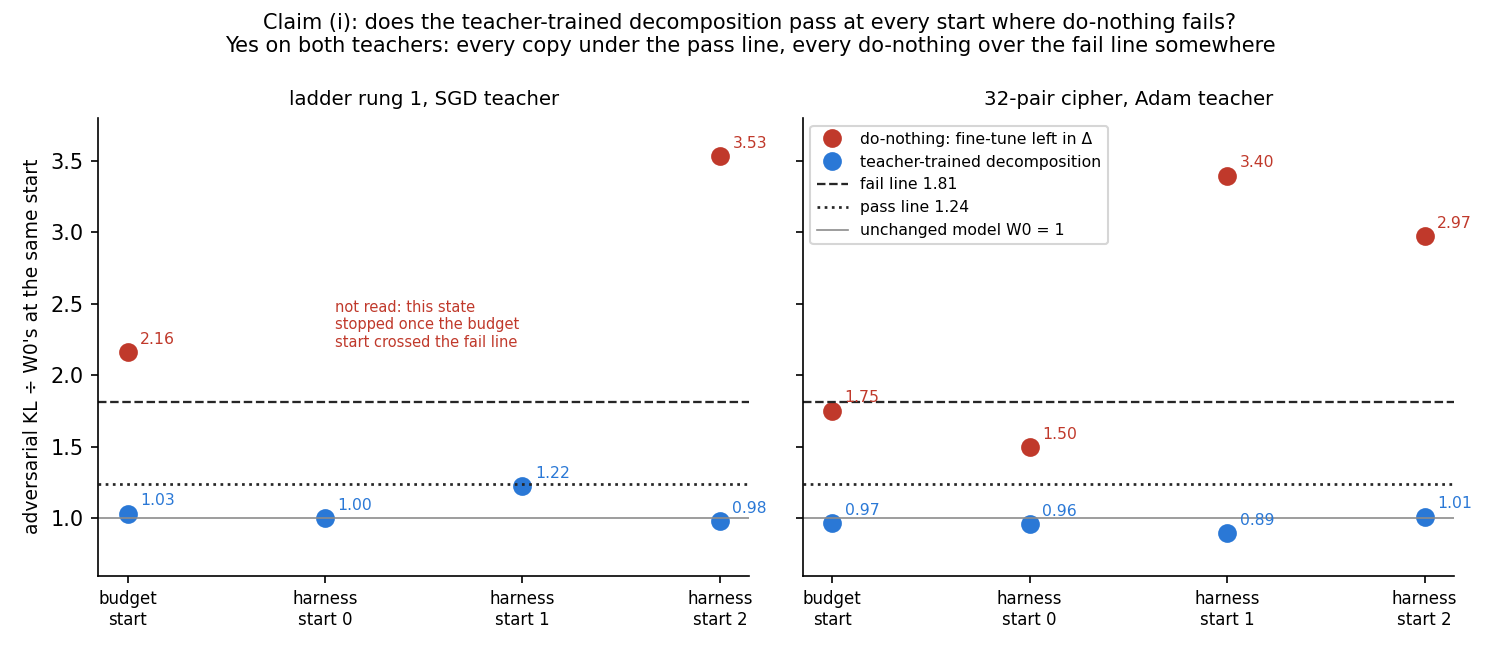

In [2]:
Image(FIG / "e47_i_teacher_training.png")

**Reading it.** The claim stands on both teachers. Every teacher-trained decomposition, in blue, sits under the dotted pass line at all four starts. Every do-nothing state, in red, crosses the dashed fail line at one start or more. On the cipher task, harness start 0 repeats the old inconclusive 1.50. Harness starts 1 and 2 then push the same state to 3.40 and 2.97. So the extra starts gave the check the power we expected it to lack. The caveat: the ladder task's teacher-trained decomposition reads 1.225 at harness start 1, only 1.3% under the pass line.

In [3]:
t1, t1b = load("t1"), load("t1b")
print(f"{'state':<16}{'worst ratio':>12}  verdict")
for s in ("r1_nothing", "r1_copy", "rand32_nothing", "rand32_copy"):
    worst = max({**t1["states"][s]["ratio"], **t1b["states"][s]["ratio"]}.values())
    print(f"{s:<16}{worst:>12.3f}  {combined['T1']['verdicts'][s]}")

state            worst ratio  verdict
r1_nothing             3.530  fail
r1_copy                1.225  pass
rand32_nothing         3.396  fail
rand32_copy            1.012  pass


### (ii) Does the rank-8 LoRA's pass hold, and does it need the low rank? It holds on one row set; the rank question is open

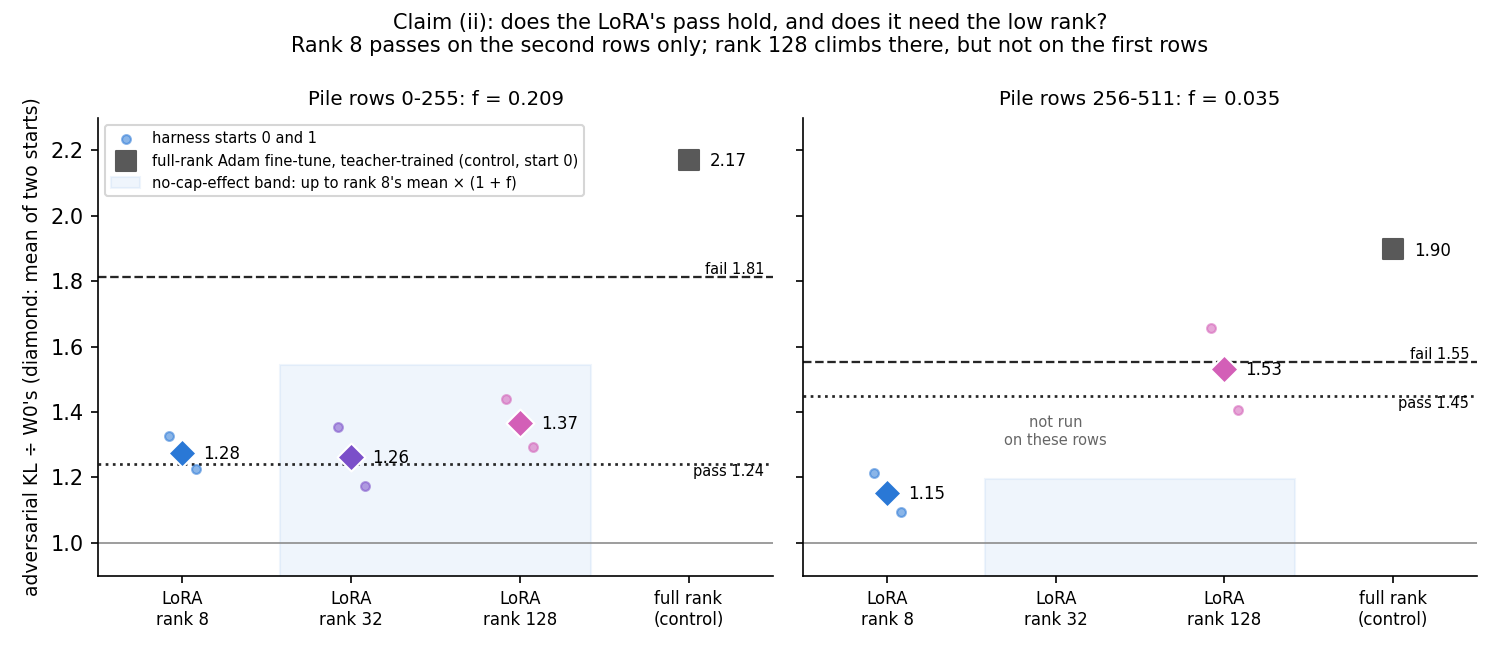

In [4]:
Image(FIG / "e47_ii_lora_rank.png")

**Reading it.** Still weakened. On Pile rows 0-255 the rank-8 LoRA's teacher-trained decomposition averages 1.28 over two starts, just over the pass line. On rows 256-511 it averages 1.15, a pass. The rank question splits the same way. On the first rows, ranks 32 and 128 sit inside rank 8's shaded band. On the second rows, rank 128 averages 1.53, a third above rank 8 and just under the fail line. The full-rank Adam control, in grey, fails on both.

Two caveats. W₀'s two starts on the second rows differ by only 3.5%, so that row set's lines and band are tight. And rank 128's update is larger than rank 32's, so a climb with rank is also a climb with size.

In [5]:
print(f"{'rows':<9}{'rank':<6}{'mean ratio':>11}{'pass line':>11}{'fail line':>11}")
for rows, stage, key, rank in (("0-255", "t2", "lora8_tt", 8), ("0-255", "t2b", "lora32_tt", 32),
                               ("0-255", "t2", "lora128_tt", 128), ("256-511", "t2c", "lora8_tt", 8),
                               ("256-511", "t2c", "lora128_tt", 128)):
    r = load(stage)
    print(f"{rows:<9}{rank:<6}{r['states'][key]['mean']:>11.3f}{r['W0']['pass_line']:>11.3f}{r['W0']['fail_line']:>11.3f}")

rows     rank   mean ratio  pass line  fail line
0-255    8           1.276      1.241      1.813
0-255    32          1.264      1.241      1.813
0-255    128         1.367      1.241      1.813
256-511  8           1.154      1.450      1.552
256-511  128         1.532      1.450      1.552


### (iii) At the same size, does a faster SGD run keep as much as a slower one? It keeps somewhat more

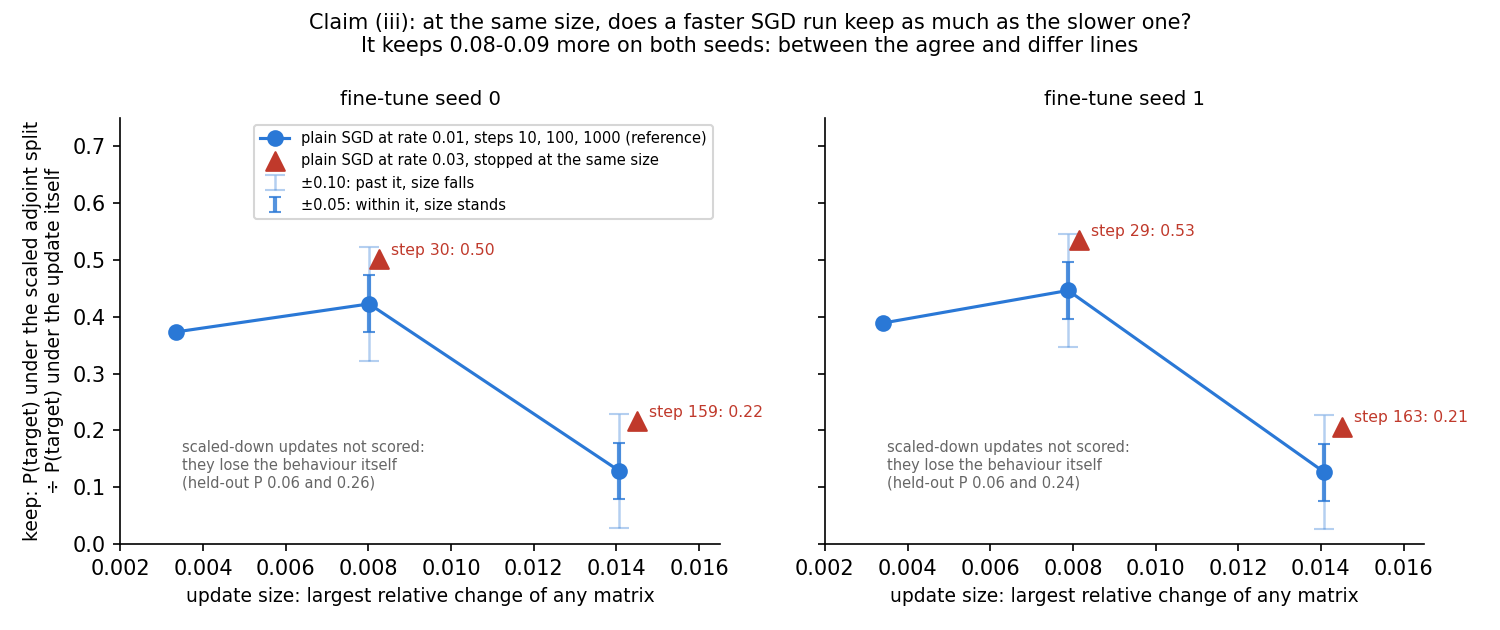

In [6]:
Image(FIG / "e47_iii_keep_size.png")

**Reading it.** Mixed on both seeds, where we had filed "falls". The blue line is the slow run at rate 0.01; the red triangles are the fast run at 0.03, stopped when it reached the same size. At both sizes and both seeds the fast run keeps 0.08 to 0.09 more. That is outside the inner bar, where size alone would stand, and inside the outer bar, where it would fall. Size still does most of the work: along either run, keep drops by about 0.3 between the two sizes.

The other half of the test, shrinking the finished update to a smaller size, could not be scored. A shrunk update loses the behaviour itself, so the keep ratio has almost nothing to divide by.

### (iv) Is teacher training plus remainder worse than do-nothing? Not at step 10

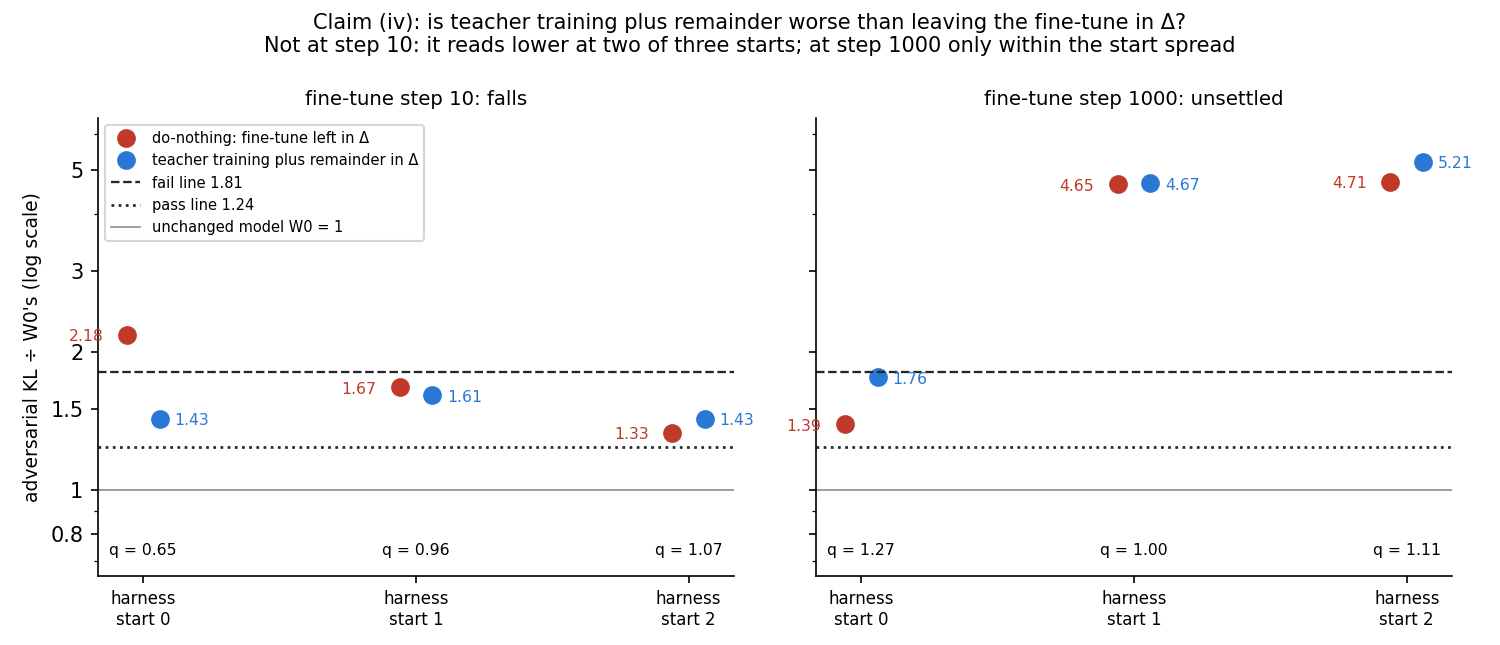

In [7]:
Image(FIG / "e47_iv_remainder.png")

**Reading it.** At fine-tune step 10 the claim falls, the reverse of our lead. $q$ is plus remainder's KL over do-nothing's at the same start; over 1 means plus remainder is worse. At harness start 0 plus remainder, in blue, reads 1.43 and do-nothing, in red, 2.18, so $q$ is 0.65. At start 1 $q$ is 0.96, at start 2 it is 1.07. E43 had found plus remainder clearly worse at this step, from one start on another card.

At step 1000 the claim stays unsettled, as filed. Plus remainder is higher at every start, but by only 0.5% at start 1, and both states fail outright at starts 1 and 2. We cannot say from these files why step 10 reversed. Every reproduction check passed.

In [8]:
for stage, step in (("t4b", 10), ("t4", 1000)):
    q = load(stage)["score"]
    print(f"step {step:>4}: q at starts 0, 1, 2 =", ", ".join(f"{q['q'][s]:.3f}" for s in ("h0", "h1", "h2")),
          "->", q["outcome"])

step   10: q at starts 0, 1, 2 = 0.654, 0.961, 1.075 -> falls
step 1000: q at starts 0, 1, 2 = 1.267, 1.005, 1.106 -> unsettled


### (v) Does teacher training with plain SGD fail the check? Only at the largest rate run longest

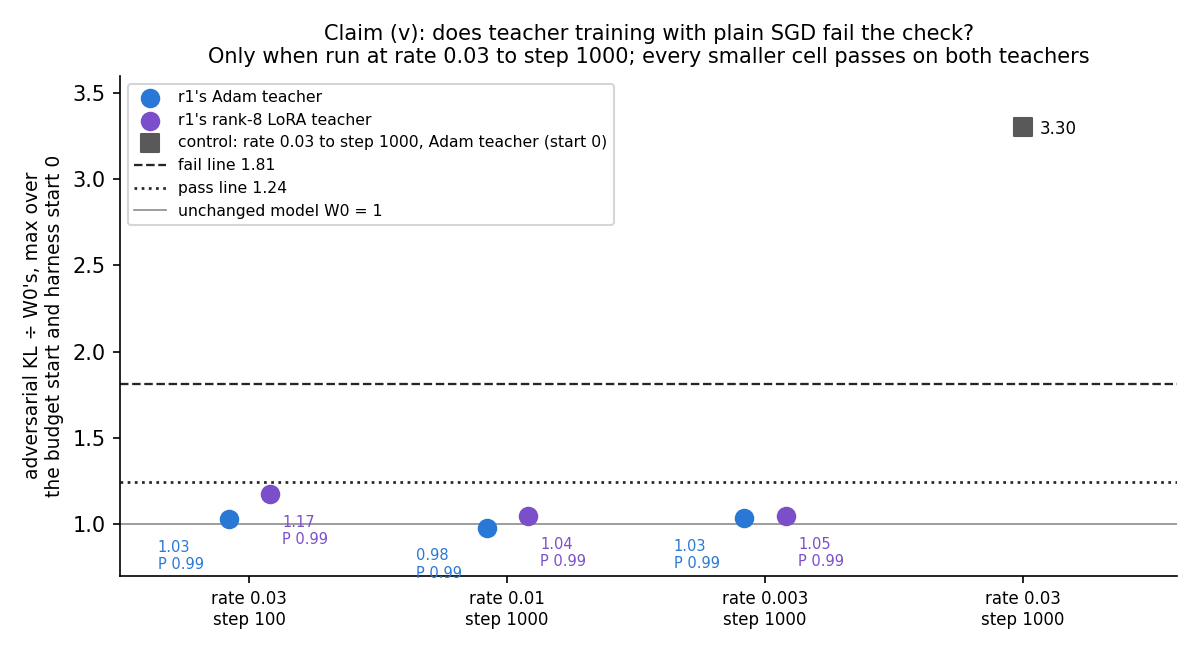

In [9]:
Image(FIG / "e47_v_plain_sgd.png")

**Reading it.** The claim falls, as we leaned. With plain SGD as teacher training's optimiser, all three smaller settings pass on both the Adam teacher and the LoRA teacher. Their worst reading over two starts is 0.98 to 1.17, and each keeps the behaviour at a probability of 0.986 or more. Only rate 0.03 run to step 1000, the setting the old claim rested on, fails, in grey. So "teacher training needs Adam" was one SGD setting, not SGD.

## What we learned

Teacher training stays the map for the weak version: its decomposition passed at four starts on two teachers where do-nothing failed. The optimiser is not what makes it work, because plain SGD passes at every smaller setting. Teacher training plus remainder is no longer known to be worse than do-nothing. The rank-8 LoRA's pass depends on which rows are read, and rank 128 shows one hint of a climb.

## How compelling is the evidence

One model, one decomposition and one card throughout. Each claim has one or two tasks and one or two seeds. Each state has two to four starts, and single states moved a lot between starts: the cipher's do-nothing went from 1.50 to 3.40. The second row set's floor comes from two starts only. Every W₀ reading, positive control and reproduction check matched. States read twice in two jobs agreed to every digit. Only the adversarial check was read.

## Surprises

1. **Something unexpected happened that I cannot explain.** We predicted that at step 10, teacher training plus remainder reads worse than do-nothing at every start. On this card it read better at two of three starts.
2. The faster SGD run kept a little more at matched size, under the line we had set for "path matters".
3. The cipher task's do-nothing failed at the extra starts, so claim (i) had power there after all.
4. W₀'s spread on the second rows was 3.5%, not the 15% the review expected.

## What next

1. Read the two step-10 states of claim (iv) at more starts and on the second rows. If plus remainder stays lower at most starts, the earlier finding was one start's reading.
2. Ranks 32 and 64 on the second rows with three starts for the floor. A climb past the fail line with rank would make the LoRA's pass a rank effect.
3. Rewrite the E34 card and `decisions.md` row 50: one plain-SGD setting fails, every smaller one passes.

## Scorecard

| id | claim | read | lean | outcome |
|---|---|---|---|---|
| T1 + T1b | (i) four starts | worst: copies 1.225, 1.012; do-nothing ≥ 3.53, 3.40 | stands r1, no power rand32 | **stands** both: miss on rand32 |
| T2 | (ii) rows 0-255 | rank 8 1.276, rank 128 1.367 | unsettled, no cap effect | unsettled, no cap effect |
| T2b | (ii) rank 32 | 1.264 vs band 1.543 | no cap effect | no cap effect |
| T2c | (ii) rows 256-511 | rank 8 1.154, rank 128 1.532 | unsettled or stands; no cap | stands; cap unsettled: **miss** |
| T3 | (iii) | +0.08 to +0.09 at matched size | falls | **mixed**: miss |
| T4 | (iv) step 1000 | q 1.27, 1.00, 1.11 | unsettled | unsettled |
| T4b | (iv) step 10 | q 0.65, 0.96, 1.07 | stands | **falls**: reversal |
| T5 + T5b | (v) three cells | six of six pass | falls | falls |

## Not run

The stochastic and CI-masked ratios; rows 256-511 for claims (i), (iv) and (v); ranks between 32 and 128; claim (iii)'s shrunk updates as scored; any check of the step-10 reversal; do-nothing references for claims (ii) and (v); other tasks, seeds, models and cards. The full list is in `reports/analyses/2026-10-29_analysis_e47-claim-tests.md`.

Provenance: `experiments/claim_tests/results/*.json`, ten MATS cluster L40 debug jobs on 2026-10-29, $0; job IDs in the report.